In [39]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler
import seaborn as sns
import plotly.express as px



# Music EDA

In [40]:
df = pd.read_csv('dataset.csv')
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Almost all of the columns are numeric.

In [41]:
df = df.drop(['Unnamed: 0'], axis=1)  
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

3 null values, we'll delete them.

In [42]:
print(df.isnull().sum())

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [43]:
df = df.dropna()

Describe in order to do a preliminar search of outliers or strange rows.

In [44]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,113999.000000,1.139990e+05,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000,113999.000000
mean,33.238827,2.280312e+05,0.566801,0.641383,5.309126,-8.258950,0.637558,0.084652,0.314907,0.156051,0.213554,0.474066,122.147695,3.904034
std,22.304959,1.072961e+05,0.173543,0.251530,3.559999,5.029357,0.480708,0.105733,0.332522,0.309556,0.190378,0.259261,29.978290,0.432623
min,0.000000,8.586000e+03,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218500,4.000000
50%,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.597500,0.049000,0.273000,0.683000,140.071000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


C:\Users\tela\AppData\Local\Temp\ipykernel_15308\4185692614.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False, patch_artist=True)
C:\Users\tela\AppData\Local\Temp\ipykernel_15308\4185692614.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False, patch_artist=True)
C:\Users\tela\AppData\Local\Temp\ipykernel_15308\4185692614.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False, patch_artist=True)
C:\Users\tela\AppData\Local\Temp\ipykernel_15308\4185692614.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13

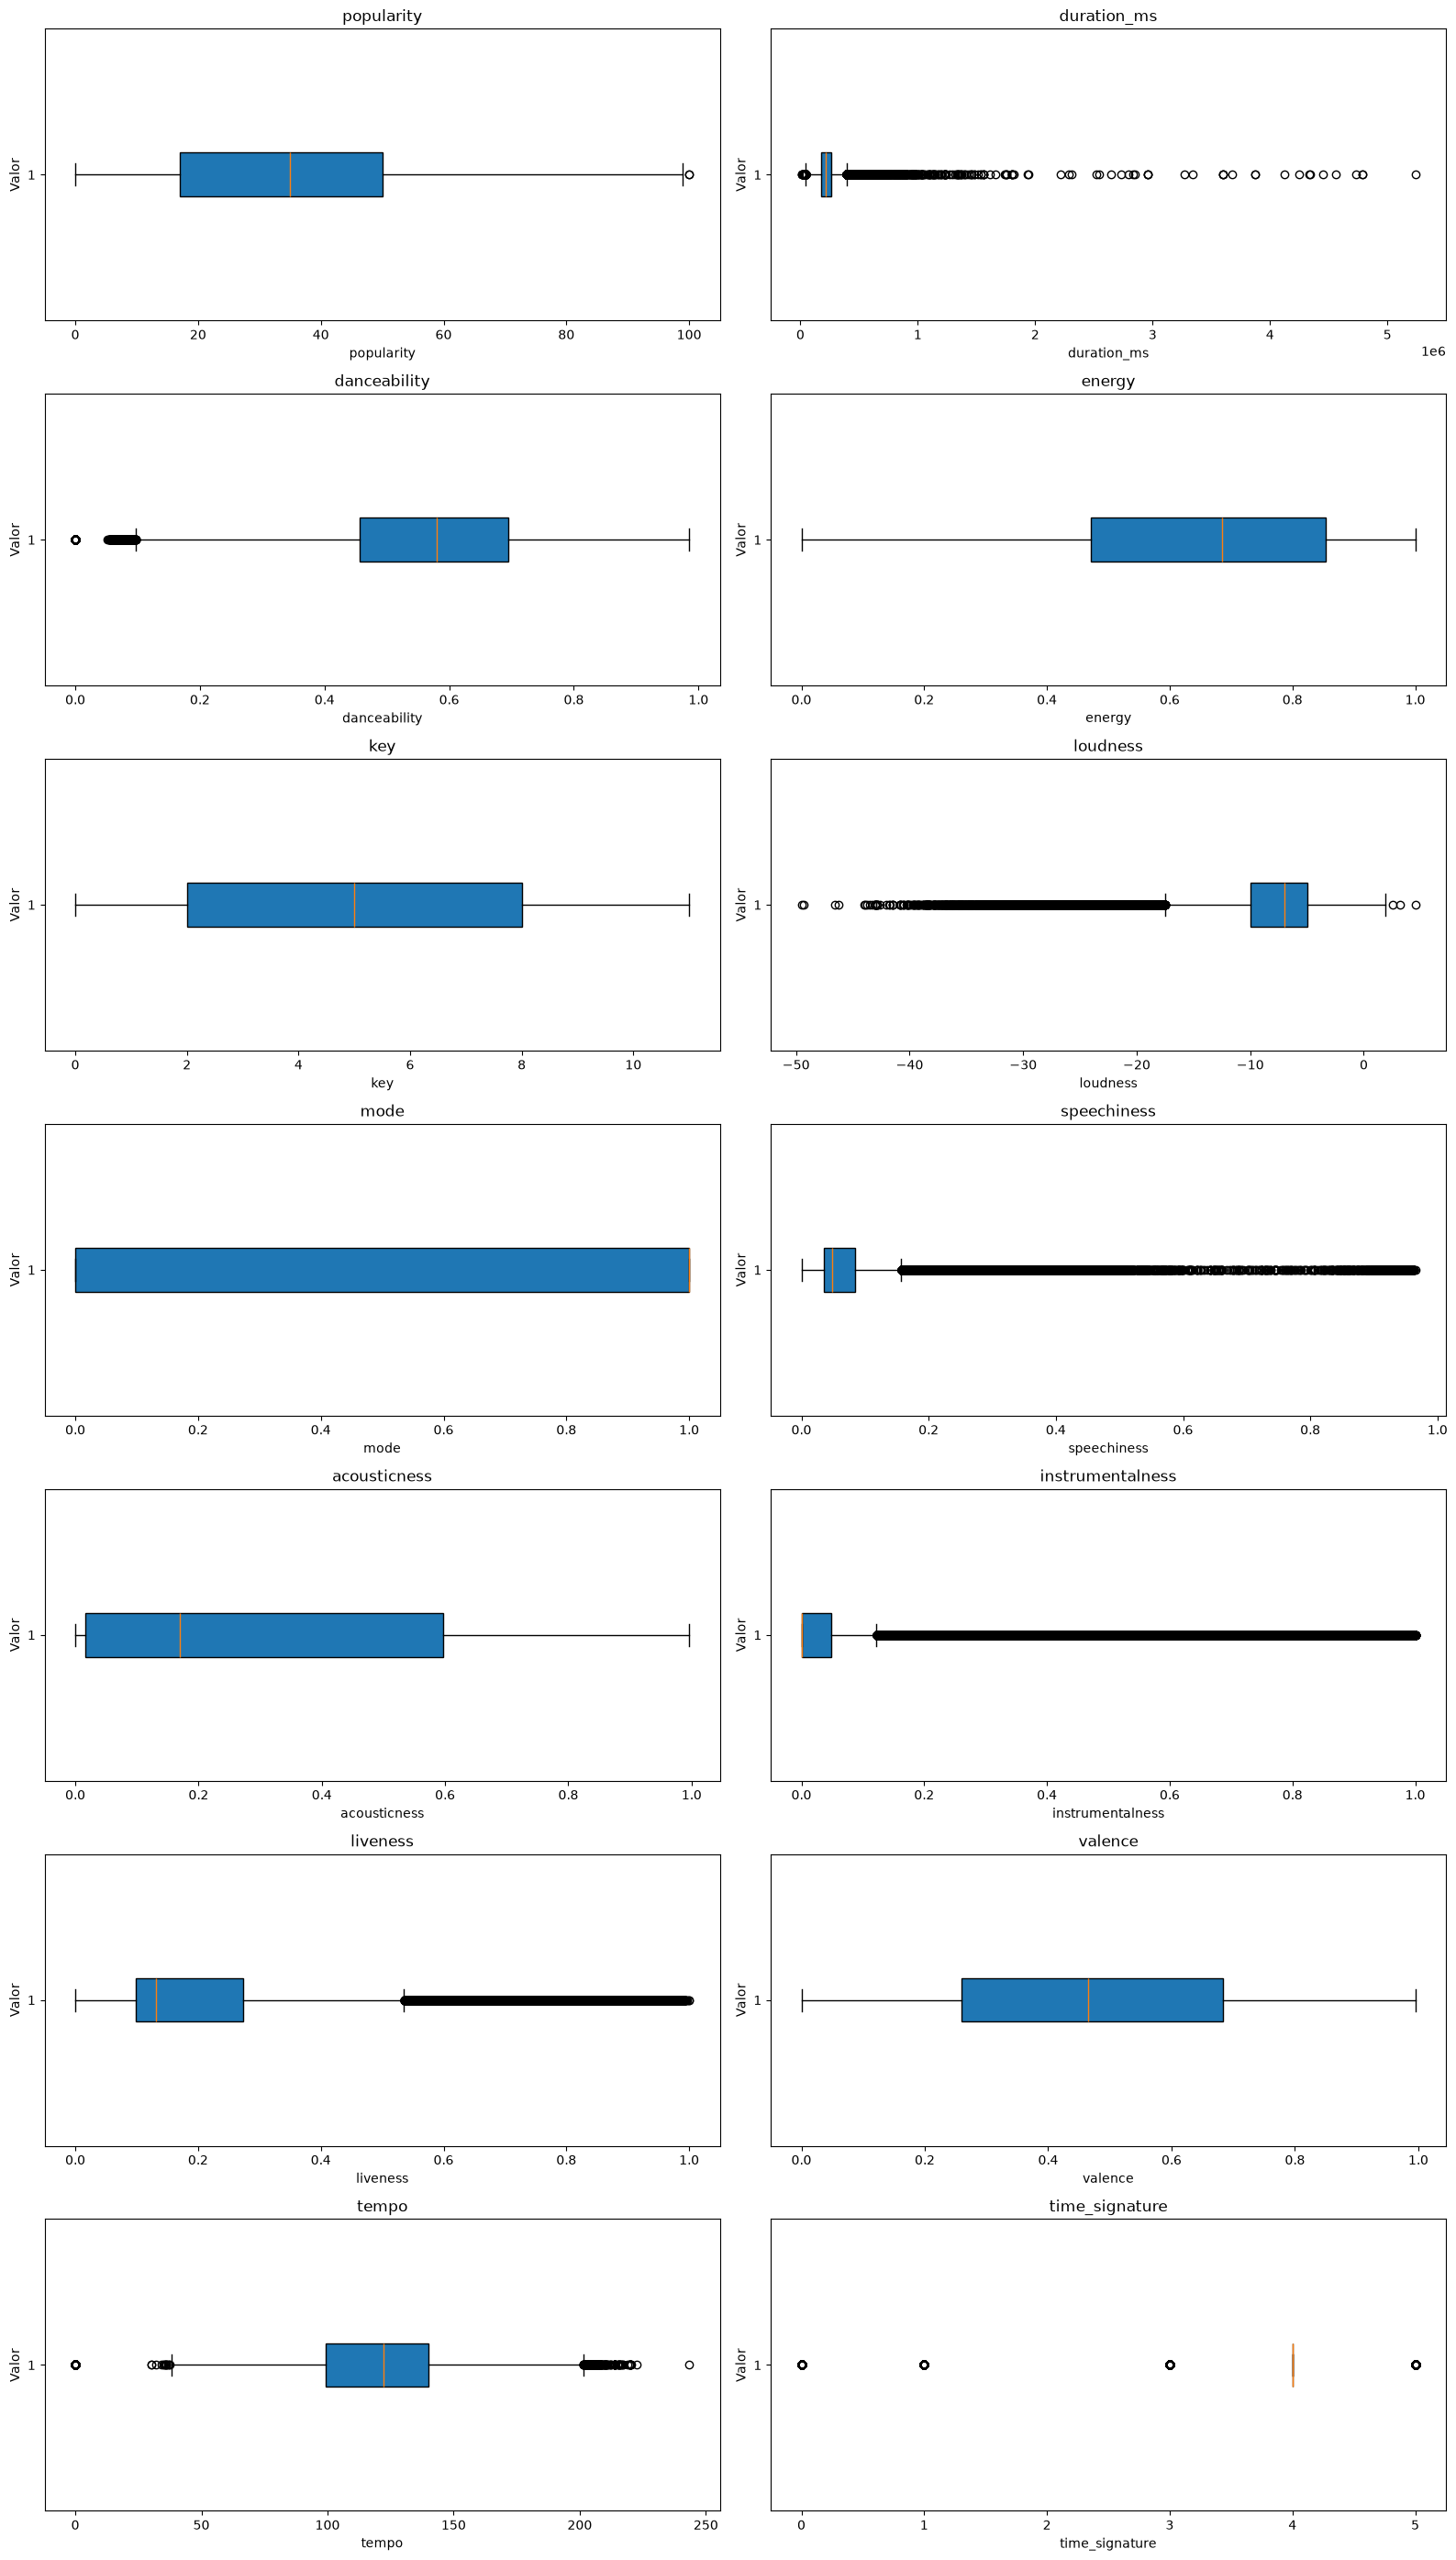

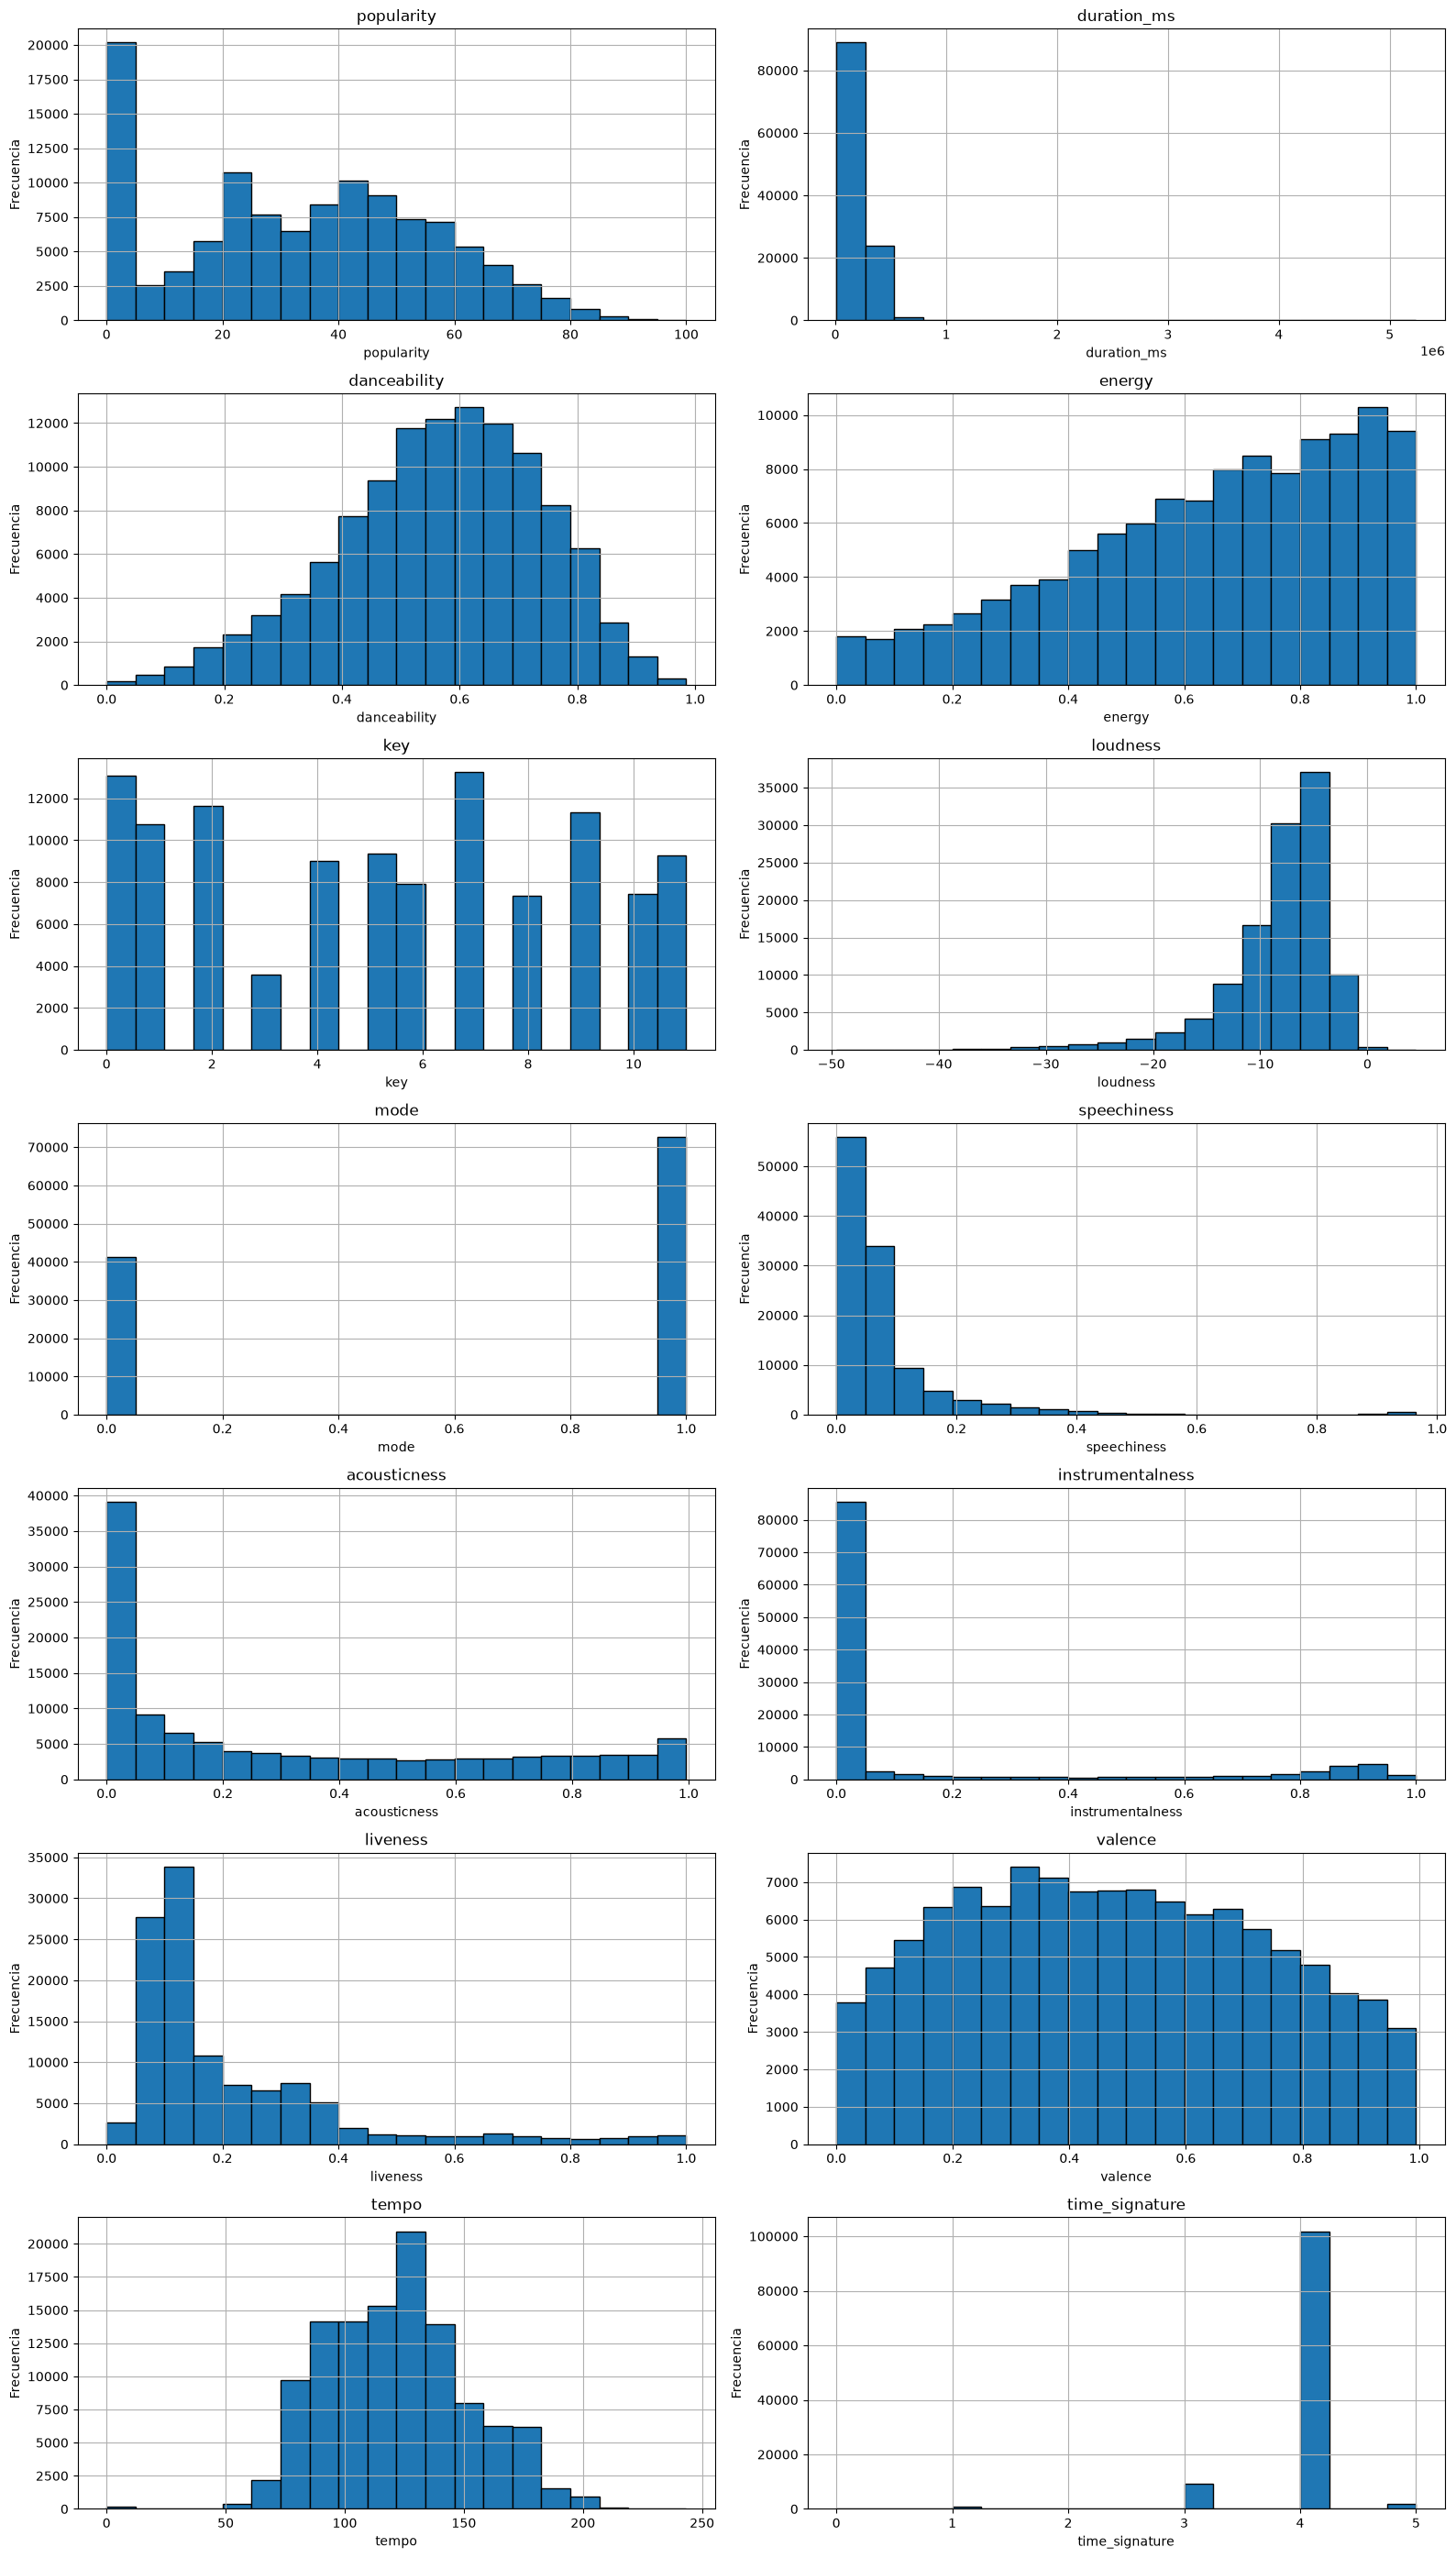

In [45]:
feature_cols = ['popularity', 'duration_ms', 'explicit', 'danceability', 'energy','key', 'loudness', 'mode', 'speechiness', 'acousticness','instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']

numeric_cols = df[feature_cols].select_dtypes(include=['number']).columns.tolist()

if numeric_cols:
    n_cols = len(numeric_cols)
    n_rows = max(1, (n_cols + 1) // 2)
    fig, axes = plt.subplots(n_rows, 2, figsize=(16, 4 * n_rows))
    axes = np.ravel(axes)

    for i, col in enumerate(numeric_cols):
        ax = axes[i]
        ax.boxplot(df[col], vert=False, patch_artist=True)
        ax.set_title(col)
        ax.set_xlabel(col)
        ax.set_ylabel('Valor')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


if numeric_cols:
    n_cols = len(numeric_cols)
    n_rows = max(1, (n_cols + 1) // 2)
    fig, axes = plt.subplots(n_rows, 2, figsize=(16, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(numeric_cols):
        ax = axes[i]
        df[col].hist(ax=ax, bins=20, edgecolor='black')
        ax.set_title(col)
        ax.set_xlabel(col)
        ax.set_ylabel('Frecuencia')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()



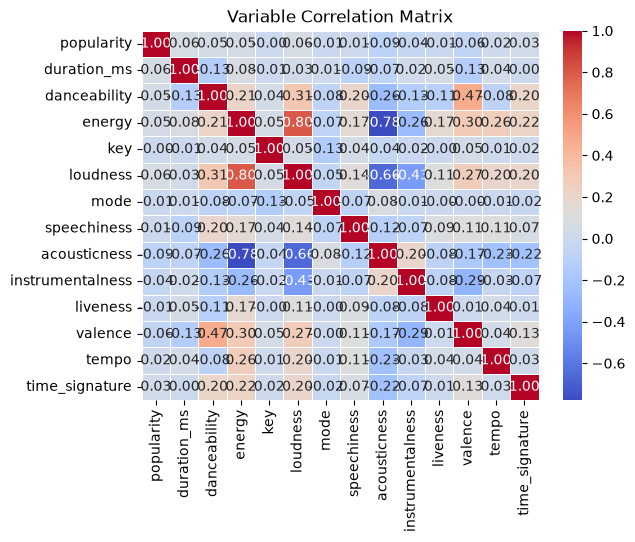

In [66]:
matriz_correlacion = df[numeric_cols].corr()

sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Variable Correlation Matrix')
plt.show()

In [67]:
generos_usados = ["pop", "k-pop","reggae", "reggaeton", "rock", "hard-rock", "punk-rock", "brazil", "ambient", "alternative", "blues", "classical", "club", "dance", "disco", "drum-and-bass", "edm", "folk", 
                  "gospel", "hardcore", "hardstyle", "heavy-metal", "hip-hop", "indie", "house", "indie-pop", "jazz", "latino", "metal", "opera", "romance", "sad", "salsa", "spanish", "study", "techno"]
df = df[df["track_genre"].isin(generos_usados)]

As there is up to 114 different genres, we'll just use the 15 most common.

In [68]:

df_original = df.copy()


scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[feature_cols]), columns=feature_cols)

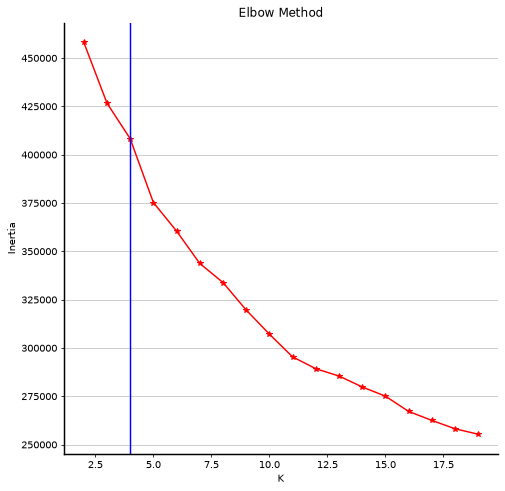

In [ ]:
sum_of_squared_distances = []
shilhouette_scores = []
K = range(2, 20)

for k in K:
    km=KMeans(n_clusters=k, random_state=42)
    y_predict = km.fit_predict(df_scaled)
    sum_of_squared_distances.append(km.inertia_)
    shilhouette_scores.append(silhouette_score(df_scaled, y_predict))

fig, ax = plt.subplots(figsize = (8,8), dpi = 70)
plt.plot(K, sum_of_squared_distances, "r-*")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.axvline(x = 4, color = "blue")
for i in ['bottom', 'left']:
    ax.spines[i].set_color('black')
    ax.spines[i].set_linewidth(1.5) 
right_side = ax.spines["right"]
right_side.set_visible(False)
top_side = ax.spines["top"]
top_side.set_visible(False)
ax.set_axisbelow(True)
ax.grid(color='gray', linewidth=1, axis='y', alpha=0.4)
plt.show()


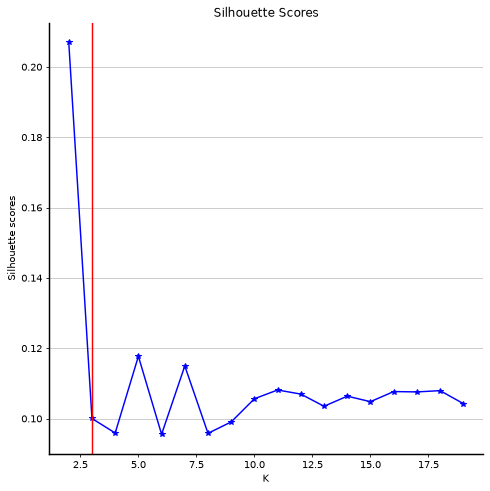

In [50]:
fig, ax = plt.subplots(figsize = (8,8), dpi = 70)
plt.plot(K, shilhouette_scores, "b-*")
plt.xlabel("K")
plt.ylabel("Silhouette scores")
plt.title("Silhouette Scores")
plt.axvline(x = 3, color = "r")
for i in ['bottom', 'left']:
    ax.spines[i].set_color('black')
    ax.spines[i].set_linewidth(1.5) 
right_side = ax.spines["right"]
right_side.set_visible(False)
top_side = ax.spines["top"]
top_side.set_visible(False)
ax.set_axisbelow(True)
ax.grid(color='gray', linewidth=1, axis='y', alpha=0.4)
plt.show()

3 Clusters is the optimal split, not enough so we won't be using them.

In [69]:
n_clusters = 3

km = KMeans(n_clusters=n_clusters, random_state=42)
df_scaled = pd.DataFrame(scaler.fit_transform(df[numeric_cols]), columns=numeric_cols, index = df.index)
#df_scaled["Cluster"] = km.fit_predict(df_scaled)


We convert the colums with the Principal Conponent Analysis to reduce dimensionality, the goal is to explain 95% of variance, whe can do that with 13 columns instead of the 17 default columns.

In [70]:
varianza_pca =PCA(n_components=0.95)
df_para_pca = df_scaled.copy()

df_pca = varianza_pca.fit_transform(df_para_pca)
n_dimensiones = df_pca.shape[1]
print(f"Número de dimensiones antes de PCA: {n_dimensiones}")
print(f"Varianza explicada acumulada: {np.sum(varianza_pca.explained_variance_ratio_):.4f}")

Número de dimensiones antes de PCA: 12
Varianza explicada acumulada: 0.9698


In [ ]:
sum_of_squared_distances = []
shilhouette_scores = []
K = range(2, 20)

for k in K:
    km=KMeans(n_clusters=k, random_state=42)
    y_predict = km.fit_predict(df_pca)
    sum_of_squared_distances.append(km.inertia_)
    shilhouette_scores.append(silhouette_score(df_pca, y_predict))

fig, ax = plt.subplots(figsize = (8,8), dpi = 70)
plt.plot(K, sum_of_squared_distances, "r-*")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.axvline(x = 4, color = "blue")
for i in ['bottom', 'left']:
    ax.spines[i].set_color('black')
    ax.spines[i].set_linewidth(1.5) 
right_side = ax.spines["right"]
right_side.set_visible(False)
top_side = ax.spines["top"]
top_side.set_visible(False)
ax.set_axisbelow(True)
ax.grid(color='gray', linewidth=1, axis='y', alpha=0.4)
plt.show()


In [54]:
pesos = pd.DataFrame(varianza_pca.components_, columns=df_para_pca.columns, index=[f'PC{i}' for i in range(1, varianza_pca.n_components_ + 1)])
print(pesos)

      popularity  duration_ms  danceability    energy       key  loudness  \
PC1     0.043736    -0.006750      0.284711  0.452194  0.050914  0.449486   
PC2    -0.119858    -0.391374      0.481938 -0.268257  0.051516 -0.175667   
PC3    -0.056039     0.029273     -0.032006  0.002032 -0.575744  0.081382   
PC4     0.505858     0.346093      0.175911 -0.007887 -0.024306  0.008634   
PC5     0.119687    -0.259321      0.100800  0.005375 -0.422679 -0.084869   
PC6     0.687782    -0.010952      0.060758 -0.096646 -0.141065 -0.054395   
PC7    -0.385455     0.210036      0.064778  0.026533 -0.158787 -0.083984   
PC8     0.127660     0.013475     -0.058038 -0.068605  0.636518 -0.070615   
PC9    -0.142132     0.766906      0.192348 -0.066874 -0.017485 -0.104244   
PC10   -0.007224    -0.152048      0.164967  0.202781  0.173966  0.092056   
PC11    0.196762     0.039855      0.189216 -0.020928 -0.039506 -0.179593   
PC12   -0.113772     0.021990      0.666429 -0.260856  0.035394  0.087219   

In [55]:
varianza = pd.DataFrame(varianza_pca.explained_variance_ratio_, index=[f'PC{i}' for i in range(1, varianza_pca.n_components_ + 1)], columns=['Varianza de PC'])
pesos_y_varianza = pd.concat([pesos, varianza], axis=1)

**What do they explain?**\
In the heatmap below it can be seen which aspects of the real columns each PC focuses more, both for positive explicability and for negative explicability:

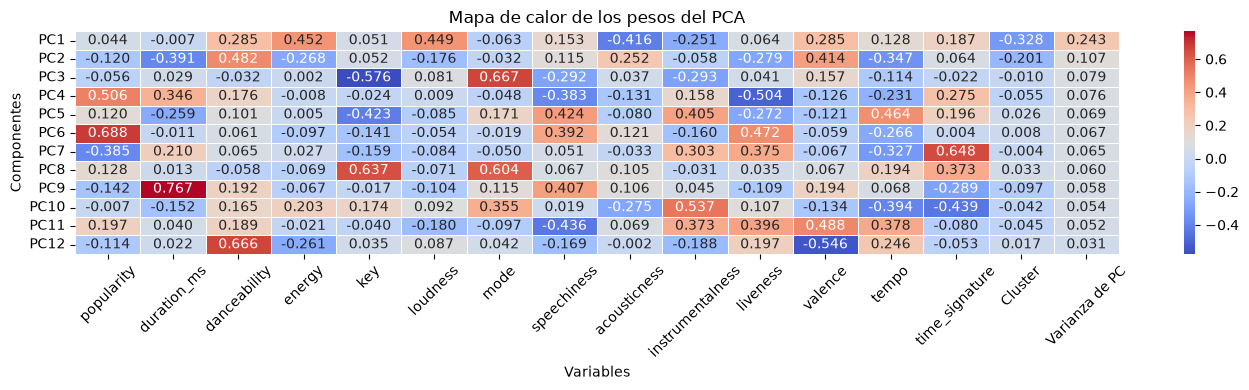

In [56]:

plt.figure(figsize=(14, 4))
sns.heatmap(
    pesos_y_varianza,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.5,
    cbar=True
)
plt.title('Mapa de calor de los pesos del PCA')
plt.xlabel('Variables')
plt.ylabel('Componentes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [57]:
pca_model = PCA(n_components=3)
X_pca_3d = pca_model.fit_transform(
    df_scaled)

fig = px.scatter_3d(
    x=X_pca_3d[:, 0],
    y=X_pca_3d[:, 1],
    
    z=X_pca_3d[:, 2],
    color=df_original["track_genre"].astype(str)
)
fig.show()

In [58]:
pca_3d = varianza_pca.fit_transform(df_scaled)
pca_3d_df = pd.DataFrame(pca_3d, columns=[f'PC{i}' for i in range(1, pca_3d.shape[1] + 1)], index = df_scaled.index)
df_pca_graficas = pd.concat([pca_3d_df, df_original[["track_id", "track_name", "artists", "album_name", "track_genre"]]], axis=1)


In [59]:
print(df_pca_graficas[df_pca_graficas["track_genre"]=="latino"])

            PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
68000  1.604832  0.203930 -0.895858 -1.556105  0.909974 -0.251480  0.201025   
68001  1.299612  1.566668 -0.020818 -0.365423  0.339123 -0.838925  0.157573   
68002  1.493885  0.525857 -1.085572 -0.702080  0.718320 -1.110709 -0.355947   
68003  1.601498  0.213066 -0.891587 -1.594664  0.900850 -0.303907  0.230407   
68004  1.248716  0.644962 -1.106475 -0.658019 -0.030196 -1.366425 -0.407690   
...         ...       ...       ...       ...       ...       ...       ...   
68995  0.003903  0.987390  1.870268 -0.487146  0.200303 -0.074783 -2.047145   
68996  0.388117 -0.541752  0.165273 -1.162963 -0.541651  1.581472  0.963630   
68997  1.646788  1.247856  0.314650 -0.442650  0.984026 -0.540807 -1.206711   
68998  1.749729  1.029777  0.092223  0.469137 -0.416957  0.043082 -0.293739   
68999 -1.912260  0.866718  1.304433 -1.490157  0.320390  0.454663 -2.108997   

            PC8       PC9      PC10      PC11      

In [60]:
df_bad_adele = df_pca_graficas.copy()
df_bad_adele = df_bad_adele[(df_bad_adele["artists"] == "Feid") | (df_bad_adele["artists"] == "ZZ Top")]
df_bad_adele.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,track_id,track_name,artists,album_name,track_genre
8010,0.342618,-1.087834,0.291106,-0.846982,-0.621796,-1.506600,-0.005344,1.310148,0.284651,-0.451444,0.267722,-0.242723,1GQMpacZAFmsYYmkT87gUw,Rough Boy,ZZ Top,Timeless Rock Hits,blues
8022,0.247964,-0.661373,0.806978,0.058235,-0.065406,-1.498720,0.266216,0.175003,-0.068339,0.152446,-0.862564,0.173883,6uPNJqmDLsgAJnNTR5V7QP,Sharp Dressed Man - 2003 Remaster,ZZ Top,80's,blues
8263,0.905074,0.636475,-0.970374,0.607523,0.211184,2.238717,0.063111,-0.872608,0.312275,-0.105056,-0.731812,-1.312519,70YvYr2hGlS01bKRIho1HM,La Grange - 2005 Remaster,ZZ Top,Tres Hombres (Expanded 2006 Remaster),blues
8530,0.974733,-0.828311,0.782425,1.543876,0.152231,0.321234,-0.837110,0.467524,-0.388290,0.247759,-0.085928,-0.083558,1UBQ5GK8JaQjm5VbkBZY66,Sharp Dressed Man - 2008 Remaster,ZZ Top,Eliminator,blues
8585,0.918380,0.810055,0.231555,0.060457,0.011197,-0.870805,-0.876002,1.444208,-0.040483,-0.207324,1.233014,-0.903645,0KbtyQ2oKJWiFJz5wY4HBX,Tube Snake Boogie,ZZ Top,The ZZ Top Sixpack,blues


Comparacion adele vs badbunny, PC1:Intensidad, energía  PC2: Musica comercial bailable PC13: Melancolia

In [61]:
fig = px.scatter_3d(
    x=df_bad_adele["PC1"],
    y=df_bad_adele["PC2"],    
    z=df_bad_adele["PC3"],
    
    color=df_bad_adele["artists"].astype(str)
)
fig.show()

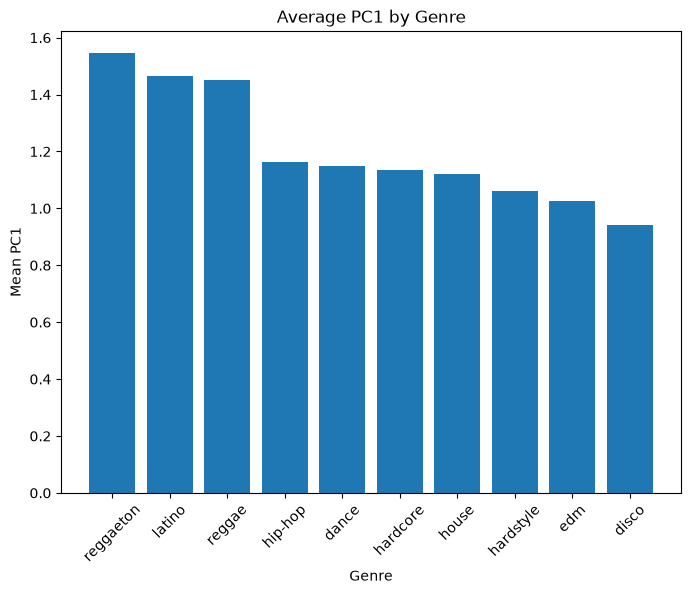

In [62]:
df_PC1_genero = df_pca_graficas.groupby('track_genre')['PC1'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 6))
plt.bar(df_PC1_genero.index, df_PC1_genero.values)
plt.xlabel('Genre')
plt.ylabel('Mean PC1')
plt.title('Average PC1 by Genre')
plt.xticks(rotation=45)
plt.show()


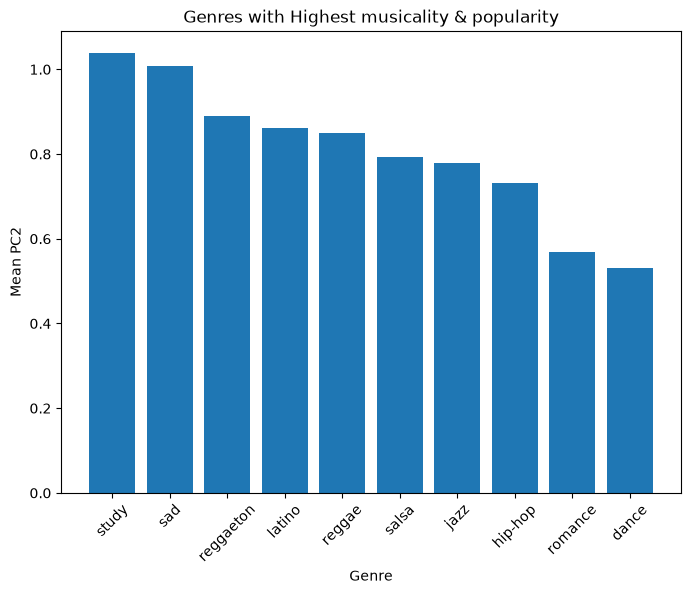

In [63]:
df_PC2_genero = df_pca_graficas.groupby('track_genre')['PC2'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 6))
plt.bar(df_PC2_genero.index, df_PC2_genero.values)
plt.xlabel('Genre')
plt.ylabel('Mean PC2')
plt.title('Genres with Highest musicality & popularity')
plt.xticks(rotation=45)
plt.show()
